In [2]:

# Now you can import config
from config import *
from Operators2D import *
import Minimal_Model_2D as mm2D
import time

In [57]:
class Quantum_Well_2D(Operators_2d):

    def Hamiltonian(self, meff):

        return hbm/meff*self.KxSq() 
    
    def Disorder_full(self, uncorr_var, lmbda=0, seed=None):
        """
        Returns a mnXmn sparse matrix with diagonal terms giving disorder potential.

        The disorder on each site is sampled from a normal distribution with variance uncorr_var and mean zero.
        This method assumes disorder is throughout the Josephson junction including superconductors, unlike dis_pot_mat method.
        
        Args: 
            uncorr_var (float): Variance of the standard normal distribution from which disorder is sampled.
            lmbda (float): To modify the magnitude of disorder.
            seed (int, optional): Seed for the random number generator to ensure reproducibility.
        """

        # Set the random seed for reproducibility
        if seed is not None:
            np.random.seed(seed)

        # Generate Gaussian distributed random numbers scaled by lambda
        gaussian_array = lmbda * np.random.normal(loc=0, scale=math.sqrt(uncorr_var), size=self.m*self.n)

        # Create a diagonal matrix of disorder potentials
        dis_array = diags(gaussian_array)

        return dis_array

    def Hamiltonian_W_disorder_uncorrelated(self, meff, uncorr_var, lmbda=0, seed=None):

        return self.Hamiltonian(meff) + self.Disorder_full(uncorr_var, lmbda, seed)



In [58]:
N = 50
M = 1

AX = 0.25
AY = 0.25

PX=False
PY= False

H = Quantum_Well_2D(N, M, AX, AY, PX, PY).Hamiltonian(1)

print(H)

  (0, 0)	1220.2365045888027
  (0, 1)	-610.1182522944014
  (1, 1)	1220.2365045888027
  (1, 2)	-610.1182522944014
  (1, 0)	-610.1182522944014
  (2, 2)	1220.2365045888027
  (2, 3)	-610.1182522944014
  (2, 1)	-610.1182522944014
  (3, 3)	1220.2365045888027
  (3, 4)	-610.1182522944014
  (3, 2)	-610.1182522944014
  (4, 4)	1220.2365045888027
  (4, 5)	-610.1182522944014
  (4, 3)	-610.1182522944014
  (5, 5)	1220.2365045888027
  (5, 6)	-610.1182522944014
  (5, 4)	-610.1182522944014
  (6, 6)	1220.2365045888027
  (6, 7)	-610.1182522944014
  (6, 5)	-610.1182522944014
  (7, 7)	1220.2365045888027
  (7, 8)	-610.1182522944014
  (7, 6)	-610.1182522944014
  (8, 8)	1220.2365045888027
  (8, 9)	-610.1182522944014
  :	:
  (41, 42)	-610.1182522944014
  (41, 40)	-610.1182522944014
  (42, 42)	1220.2365045888027
  (42, 43)	-610.1182522944014
  (42, 41)	-610.1182522944014
  (43, 43)	1220.2365045888027
  (43, 44)	-610.1182522944014
  (43, 42)	-610.1182522944014
  (44, 44)	1220.2365045888027
  (44, 45)	-610.11825229

In [59]:
E, V = eigsh(H, k=4, sigma=0)

In [60]:
print(E)

[ 2.31438751  9.24877078 20.77684533 36.8548812 ]


In [61]:
hbm*math.pi**2/(N+1)**2/AX**2

2.315119487900719

In [62]:
hbm*math.pi**2*(1/(N+1)**2/AX**2)

2.3151194879007195

In [63]:
hbm*math.pi**2*(1/(N+1)**2/AX**2)*4

9.260477951602878

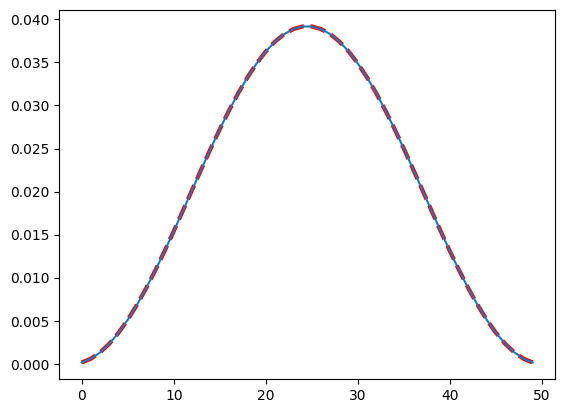

In [66]:
plt.plot((2/(N+1))*np.sin((np.arange(N)+1)*math.pi*1/(N+1))**2 , color='red', linestyle='dashed', lw=3)
plt.plot(abs(V[:,0])**2)

In [92]:
#LMBDA = np.array([0, 1e-5, 1e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1, 1])
#LMBDA = np.linspace(0,0.2, 100)
LMBDA = np.linspace(0,1, 100)
UNCORR_VAR = 1000
SEED = 42
KNUM  = 8 

N = 50
M = 1

AX = 0.25
AY = 0.25

PX=False
PY= False

Eplot = np.empty((KNUM,LMBDA.shape[0]))

for i in range(LMBDA.shape[0]):

    H = Quantum_Well_2D(N, M, AX, AY, PX, PY).Hamiltonian_W_disorder_uncorrelated(1, UNCORR_VAR, LMBDA[i])

    E = eigsh(H, k=KNUM, sigma=0, return_eigenvectors=False)

    # Get the indices that would sort Ecu
    sorted_indices = np.argsort(E)

    # Sort Ecu using the sorted indices
    sorted_E = E[sorted_indices]

    # Sort the columns of V according to the sorted indices
    #sorted_V = V[:, sorted_indices]

    Eplot[:,i] = sorted_E

    if i%10 == 0:

        print(i)

    

0
10
20
30
40
50
60
70
80
90


In [80]:
LMBDA.shape

(10,)

In [81]:
Eplot.shape

(8, 10)

IndexError: index 8 is out of bounds for axis 0 with size 8

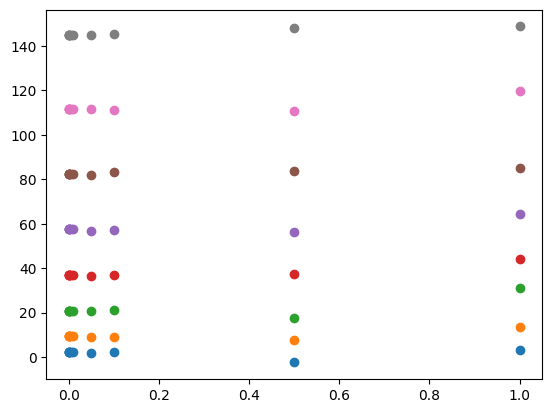

In [82]:

for i in range(LMBDA.shape[0]):
    plt.scatter(LMBDA, Eplot[i,:])

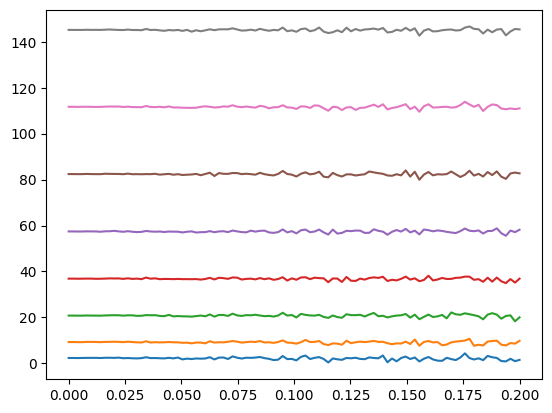

In [86]:

for i in range(KNUM):
    plt.plot(LMBDA, Eplot[i,:])

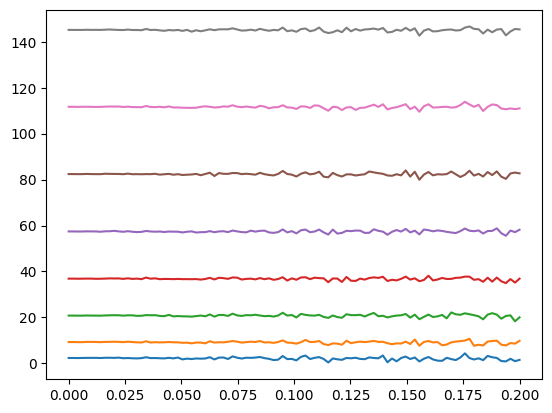

In [87]:

for i in range(KNUM):
    plt.plot(LMBDA, Eplot[i,:])

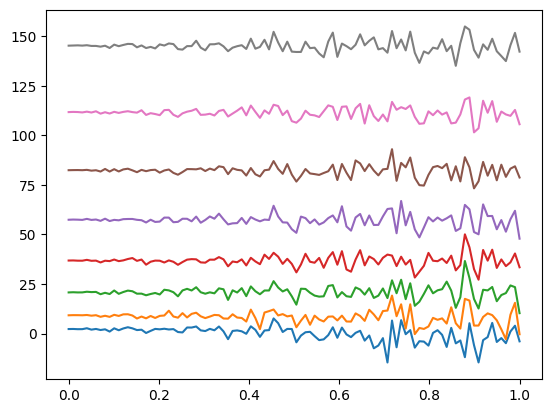

In [93]:
for i in range(KNUM):
    plt.plot(LMBDA, Eplot[i,:])

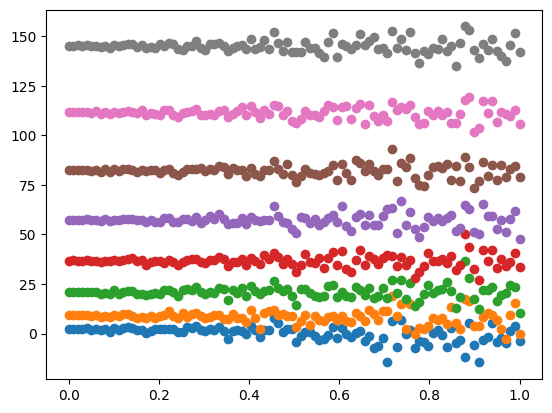

In [94]:
for i in range(KNUM):
    plt.scatter(LMBDA, Eplot[i,:])